---
A Notebook that shows the different input (n, k) data that goes into our physics model

calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
Global variables:
	PROJECT_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
	OPTICS_DATA_PATH =  /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	LITERA

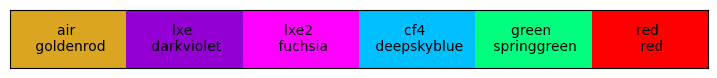

In [2]:
from scipy.stats import norm

import os
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.ndimage import gaussian_filter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Circle

from DAAPS_TOOLKIT.GenPaths import *
PrintDAAPSGlobalVariables()

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors()

rad2deg = 180/np.pi




laser hits all SiPMs with some occupancy O  
Occupancy: probability of seeing 1 photon when laser fires

SiPM A  
occupancy $O_A$

SiPM B  
occupancy $O_B$


Mode 1:  
SiPM A is turned on, sipmB off
- measure $O_A$

Mode 2: 
SiPM A is turned off, SiPM B is turned on
- measure $O_B$

Mode 3:  
Then we turn both on, count number (0, 1) events.

$P(0, 1) = O_B * (1 - O_A) * (1 - P_{Exct, BA})$

$T_{BA}$ - transport from B to A

$P_{Exct, BA} = N_{xe} * T_{BA} * PDE$


$T_{LP} \approx 90\%$


$P_{Exct, CA} = \frac{T_{LP}}{1.0} P_{Exct, CA}$











In [35]:
dhDefault = OpticsData()# for index of refraction data, etc.

print("quartz n at 600nm", dhDefault.OxideIndex(600))

photonTest_vac = PhotonInfo(650, np.array([0, 45]), dataHelper=dhDefault, mediumStr="vacuum")
photonTest_cff = PhotonInfo(650, np.array([0, 45, 60]), dataHelper=dhDefault, mediumStr="cf4")

print(photonTest_vac.PrintPhotonInfo())

print(photonTest_cff.PrintPhotonInfo())

quartz n at 600nm (1.4565+0j)
-- Photon Information: 650 nm --
Theta1: [ 0. 45.] degrees
Theta2: [ 0.        +0.j 29.07039674+0.j] degrees
Theta3: [ 0.        +0.j         10.55055998-0.05034919j] degrees
Pure R, T 1<->2: [0.03438636 0.04404926][0.96561364 0.95595074]
Pure R, T 2<->3: [0.20484421 0.20590533], [0.79515579 0.79409402]

['Theta1: [ 0. 45.] degrees', 'Theta2: [ 0.        +0.j 29.07039674+0.j] degrees', 'Theta3: [ 0.        +0.j         10.55055998-0.05034919j] degrees', 'Pure R, T 1<->2: [0.03438636 0.04404926][0.96561364 0.95595074]', 'Pure R, T 2<->3: [0.20484421 0.20590533], [0.79515579 0.79409402]']
-- Photon Information: 650 nm --
Theta1: [ 0. 45. 60.] degrees
Theta2: [ 0.        +0.j 35.99931323+0.j 46.04416914+0.j] degrees
Theta3: [ 0.        +0.j         12.79717957-0.06140312j 15.74053845-0.07619233j] degrees
Pure R, T 1<->2: [0.00849274 0.0128595  0.0340413 ][0.99150726 0.9871405  0.9659587 ]
Pure R, T 2<->3: [0.20484421 0.20752619 0.21311401], [0.79515579 0.7924

---
### Final (Default) merged outputs

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silico

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


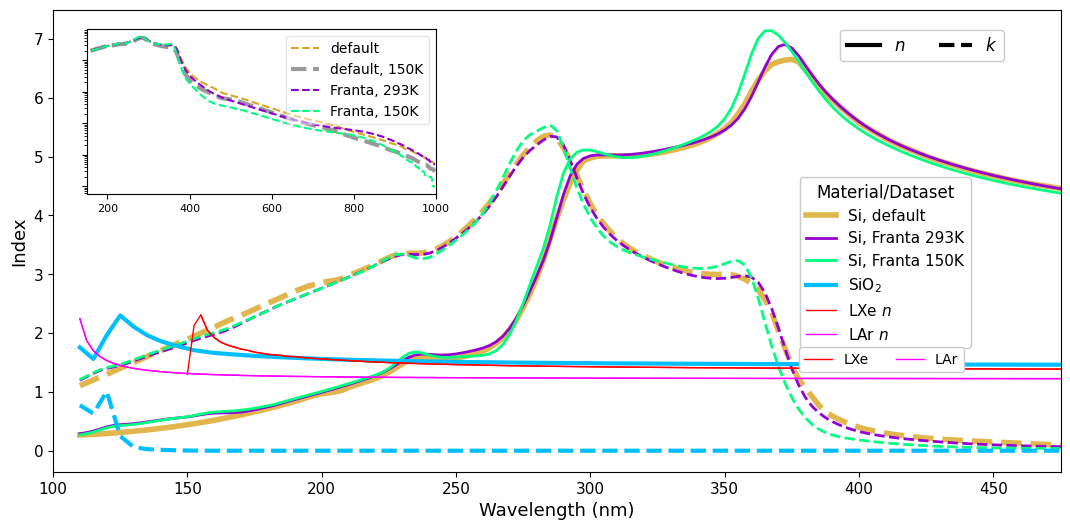

In [22]:
## overlapping the default (good) data
from matplotlib.ticker import MultipleLocator

fig, ax = plt.subplots(1, 1, figsize = (13,6))

wlen = np.arange(110, 1000, 2.5)

ms.ResetColorCycle()
OpticsData.ResetInstance()
dhDefault = OpticsData()

dhFranta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta_rt = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))

## looking at the temp corrected default data
# photonDefault_warm = PhotonInfo(wlen = wlen, theta_1 = 0, materialTemp=None, dataHelper= dhDefault)
photonDefault = PhotonInfo(wlen = wlen, theta_1 = 0, materialTemp=150, dataHelper= dhDefault)
cold_mu = photonDefault.muSi
k_default_cold = ME.kFromMu(wlen, cold_mu)

thickDict = {"linewidth": 4, "alpha": 0.8}
allLines = {"linewidth": 2}

# ax.plot([0], [0], linestyle = "-", color ="k", label = r"$n$")
# ax.plot([0], [0], linestyle = "--", color ="k", label = r"$k$")

# si default
ax.plot(wlen, dhDefault.SiIndex(wlen).real, color = ms.air.col, label = "Si, default", **thickDict)
ax.plot(wlen, dhDefault.SiIndex(wlen).imag, color = ms.air.col, linestyle = "--", **thickDict)

# si franta 293K
ax.plot(wlen, dhFranta_rt.SiIndex(wlen).real, color =  ms.lxe.col, label = "Si, Franta 293K", **allLines)
ax.plot(wlen, dhFranta_rt.SiIndex(wlen).imag, color = ms.lxe.col, linestyle = "--", **allLines)

# si franta 150K
ax.plot(wlen, dhFranta.SiIndex(wlen).real, color = ms.green.col, label = "Si, Franta 150K", **allLines)
# print(dhFranta.SiIndex(wlen).real)
ax.plot(wlen, dhFranta.SiIndex(wlen).imag, color = ms.green.col, linestyle = "--", **allLines)

## dont need text box
# box=dict(facecolor='red', alpha=0.2, edgecolor='black', boxstyle='round,pad=1')
# ax.text(130,6., f"Default data:\n{os.path.basename(dhDefault.mPathSi)} \n{os.path.basename(dhDefault.mPathSiO2)}", fontsize = 8, bbox = box, transform = ax.transData)

# sio2
ax.plot(wlen, dhDefault.OxideIndex(wlen).real, color = ms.cf4.col, label = r"SiO$_2$", linewidth = 3)
ax.plot(wlen, dhDefault.OxideIndex(wlen).imag, color = ms.cf4.col, linestyle = "--", linewidth = 3)

## nobles
dhDefault.Load_LXe_nData()
dnoble = {"linewidth": 1, "alpha": 1.0, "linestyle": "-"}
xeMask = (wlen >= 155) & (wlen <= 825) ## from resonances in grace paper
ax.plot(wlen[xeMask], dhDefault.LXeIndex(wlen)[xeMask], color = ms.red.col, label = r"LXe $n$", **dnoble)
# ax.plot(wlen, dhDefault.LXeIndex_Sellmeier(wlen), color = ms.red.col, label = r"LXe $n$", **dnoble)

arMask = (wlen >= 105) & (wlen <= 900) ## from resonances in grace paper
ax.plot(wlen[arMask], dhDefault.LArIndex(wlen)[arMask], color = ms.lxe2.col, label = r"LAr $n$", **dnoble) 


## adding inset graph
# axins = ax.inset_axes([0.27, 0.05, 0.4, 0.35])
spot = (110, 4.25, 130, 2.8)
# spot = (395, 1.8, 150, 2.3)
axins = inset_axes(ax, width="100%", height="100%", loc="lower left", bbox_to_anchor=spot, bbox_transform=ax.transData)

axins.semilogy(wlen, dhDefault.SiIndex(wlen).imag, color = ms.air.col, linestyle = "--", label = "default")
axins.semilogy(wlen, k_default_cold, color = "gray", linestyle = "--", linewidth=3, alpha = 0.8,label = "default, 150K")

axins.semilogy(wlen, dhFranta_rt.SiIndex(wlen).imag, color = ms.lxe.col, linestyle = "--", label = "Franta, 293K")
axins.semilogy(wlen, dhFranta.SiIndex(wlen).imag, color = ms.green.col, linestyle = "--", label = "Franta, 150K")

# axins.set_alpha(0.0)
axins.patch.set_facecolor((1, 1, 1, 0.5))  # Set background to white with 50% transparency

# axins.tick_params(axis='y', labelsize=8)
axins.set_yticklabels([])

axins.tick_params(axis='x', labelsize=8)
axins.xaxis.set_major_locator(MultipleLocator(200))  # X ticks every 100nm

axins.set_xlim(150, 1000)
# axins.set_ylim(1e-3, 1)

axins.legend(loc='upper right', title_fontsize = 11, fontsize=10, title=None, framealpha=0.5)
## 

ax.set_xlim(100, 475)
# ax.set_xlim(400, 800)

stuckTogether = (375, 1.61)
leg1 = ax.legend(title = "Material/Dataset", loc = "lower left",
          bbox_to_anchor=stuckTogether,  # Exact location in data coordinates
          bbox_transform=ax.transData,
          fontsize = 11, title_fontsize = 12, framealpha=1.0)
ax.add_artist(leg1)  # Add the first legend to the axes

## n, k legend
legend2 = ax.legend(loc = "upper left",
    handles=[
        ax.plot([], [], linestyle="-", linewidth=3, color="k", label=r"$n$")[0],
        ax.plot([], [], linestyle="--", linewidth=3, color="k", label=r"$k$")[0]
    ],
    bbox_to_anchor=(390, 7.3),  # Exact location in data coordinates
    bbox_transform=ax.transData,
    prop={"weight": "bold", "size":12}, framealpha=1.0, ncol=2
)
ax.add_artist(legend2)  # Add the second legend to the axes

legend3 = ax.legend(loc = "upper left",
    handles=[
        ax.plot(wlen[wlen >= 150], dhDefault.LXeIndex(wlen)[wlen >= 150], color = ms.red.col, label = "LXe", **dnoble)[0],
        ax.plot(wlen, dhDefault.LArIndex(wlen), color = ms.lxe2.col, label = "LAr", **dnoble)[0]
    ],
    bbox_to_anchor=(stuckTogether[0], stuckTogether[1]+0.27),  # Exact location in data coordinates
    bbox_transform=ax.transData,
    fontsize = 10, title_fontsize = 11, framealpha=1.0, ncol=2
)

######
fdict = {"fontsize": 13}

ax.tick_params(axis='both', which='major', labelsize=11)
ax.set_xlabel("Wavelength (nm)", **fdict)
ax.set_ylabel("Index", **fdict)
# ax.set_title("Input Optical data", fontsize = 18)
plt.show()

In [4]:
## comparing transmission between n values for LXe
wlTest = 1000
t1p35 = ME.Wave_TwoLayerTransmission_total_noThetas(wlen = wlTest, thick = 16.5, theta1 = 0, n1 = 1.35, n2 = dhDefault.OxideIndex(wlTest), n3 = dhDefault.SiIndex(wlTest))


t1p4 = ME.Wave_TwoLayerTransmission_total_noThetas(wlen = wlTest, thick = 16.5, theta1 = 0, n1 = 1.4, n2 = dhDefault.OxideIndex(wlTest), n3 = dhDefault.SiIndex(wlTest))
print(t1p35-t1p4)
print("ratio 1.4/1.35 = ", np.abs(t1p35-t1p4)/t1p35 * 100, "%")

tt1 = 0
nt1 = 1.4
tp1 = ME.Fresnel_RefAndTrans(n1=nt1, n2 = dhDefault.SiIndex(wlTest), theta1=0, theta2=ME.Snells_Law(n1=nt1, n2=dhDefault.SiIndex(wlTest), theta1=0))

tp2 = ME.Fresnel_RefAndTrans(n1=1.35, n2 = dhDefault.SiIndex(wlTest), theta1=0, theta2=ME.Snells_Law(n1=1.35, n2=dhDefault.SiIndex(wlTest), theta1=0))

print(tp1[1], tp2[1])


(-0.01245324835620798+0j)
ratio 1.4/1.35 =  (1.5626335120299242+0j) %
0.8088577718659384 0.7958869881591188


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silico

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


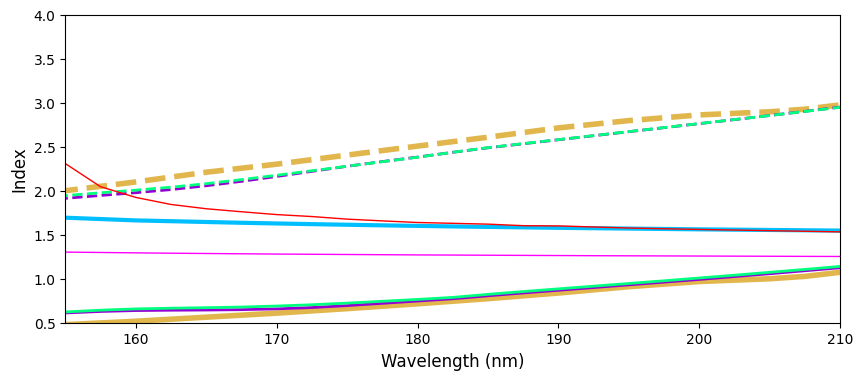

fiinal lxe values: 1.3466158184026158 1.3504807210754706
final lar values: 1.2215140037662258 1.2327691791259996


In [5]:
## overlapping the default (good) data

fig, ax = plt.subplots(1, 1, figsize = (10,4))

wlen = np.arange(110, 1000, 2.5)

ms.ResetColorCycle()
OpticsData.ResetInstance()
dhDefault = OpticsData()

dhFranta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta_rt = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))

## looking at the temp corrected default data
# photonDefault_warm = PhotonInfo(wlen = wlen, theta_1 = 0, materialTemp=None, dataHelper= dhDefault)
photonDefault = PhotonInfo(wlen = wlen, theta_1 = 0, materialTemp=150, dataHelper= dhDefault)
cold_mu = photonDefault.muSi
k_default_cold = ME.kFromMu(wlen, cold_mu)

thickDict = {"linewidth": 4, "alpha": 0.8}
allLines = {"linewidth": 2}

# ax.plot([0], [0], linestyle = "-", color ="k", label = r"$n$")
# ax.plot([0], [0], linestyle = "--", color ="k", label = r"$k$")

# si default
ax.plot(wlen, dhDefault.SiIndex(wlen).real, color = ms.air.col, label = "Si, default", **thickDict)
ax.plot(wlen, dhDefault.SiIndex(wlen).imag, color = ms.air.col, linestyle = "--", **thickDict)

# si franta 293K
ax.plot(wlen, dhFranta_rt.SiIndex(wlen).real, color =  ms.lxe.col, label = "Si, Franta 293K", **allLines)
ax.plot(wlen, dhFranta_rt.SiIndex(wlen).imag, color = ms.lxe.col, linestyle = "--", **allLines)

# si franta 150K
ax.plot(wlen, dhFranta.SiIndex(wlen).real, color = ms.green.col, label = "Si, Franta 150K", **allLines)
# print(dhFranta.SiIndex(wlen).real)
ax.plot(wlen, dhFranta.SiIndex(wlen).imag, color = ms.green.col, linestyle = "--", **allLines)

## dont need text box
# box=dict(facecolor='red', alpha=0.2, edgecolor='black', boxstyle='round,pad=1')
# ax.text(130,6., f"Default data:\n{os.path.basename(dhDefault.mPathSi)} \n{os.path.basename(dhDefault.mPathSiO2)}", fontsize = 8, bbox = box, transform = ax.transData)

# sio2
ax.plot(wlen, dhDefault.OxideIndex(wlen).real, color = ms.cf4.col, label = r"SiO$_2$", linewidth = 3)
ax.plot(wlen, dhDefault.OxideIndex(wlen).imag, color = ms.cf4.col, linestyle = "--", linewidth = 3)

## nobles
dhDefault.Load_LXe_nData()
dnoble = {"linewidth": 1, "alpha": 1.0, "linestyle": "-"}
xeMask = (wlen >= 155) & (wlen <= 825) ## from resonances in grace paper
ax.plot(wlen[xeMask], dhDefault.LXeIndex(wlen)[xeMask], color = ms.red.col, label = r"LXe $n$", **dnoble)
# ax.plot(wlen, dhDefault.LXeIndex_Sellmeier(wlen), color = ms.red.col, label = r"LXe $n$", **dnoble)

arMask = (wlen >= 105) & (wlen <= 890) ## from resonances in grace paper
ax.plot(wlen[arMask], dhDefault.LArIndex(wlen)[arMask], color = ms.lxe2.col, label = r"LAr $n$", **dnoble) 


############ adding inset graph
# # axins = ax.inset_axes([0.27, 0.05, 0.4, 0.35])
# spot = (630, 4.3, 355, 3.2)
# # spot = (395, 1.8, 150, 2.3)
# axins = inset_axes(ax, width="100%", height="100%", loc="lower left", bbox_to_anchor=spot, bbox_transform=ax.transData)

# axins.semilogy(wlen, dhDefault.SiIndex(wlen).imag, color = ms.air.col, linestyle = "--", label = "default")
# axins.semilogy(wlen, k_default_cold, color = "gray", linestyle = "--", linewidth=3, alpha = 0.8,label = "default, 150K")

# axins.semilogy(wlen, dhFranta_rt.SiIndex(wlen).imag, color = ms.lxe.col, linestyle = "--", label = "Franta, 293K")
# axins.semilogy(wlen, dhFranta.SiIndex(wlen).imag, color = ms.green.col, linestyle = "--", label = "Franta, 150K")


# # axins.set_alpha(0.0)
# axins.patch.set_facecolor((1, 1, 1, 0.5))  # Set background to white with 50% transparency

# axins.tick_params(axis='y', labelsize=8)
# axins.tick_params(axis='x', labelsize=8)
# axins.set_xlim(400, max(wlen))
# axins.set_ylim(1e-3, 1)

# axins.legend(loc='upper right', title_fontsize = 9, fontsize=8, title=None, framealpha=0.5)
# ###### done inset axes

ax.set_xlim(100, 1000)
# ax.set_ylim(ax.get_ylim()[0], 8)

stuckTogether = (100, 8)
leg1 = ax.legend(title = "Material/Dataset", loc = "upper left",
          bbox_to_anchor=stuckTogether,  # Exact location in data coordinates
          bbox_transform=ax.transData,
          fontsize = 8, title_fontsize = 9, framealpha=1.0)
ax.add_artist(leg1)  # Add the first legend to the axes

# n, k legend
legend2 = ax.legend(loc = "upper left",
    handles=[
        ax.plot([], [], linestyle="-", linewidth=1, color="k", label=r"$n$")[0],
        ax.plot([], [], linestyle="--", linewidth=1, color="k", label=r"$k$")[0]
    ],
    bbox_to_anchor= (stuckTogether[0], stuckTogether[1]-3.5),  # Exact location in data coordinates
    bbox_transform=ax.transData,
    prop={"weight": "bold", "size":8}, framealpha=1.0, ncol=2
)
ax.add_artist(legend2)  # Add the second legend to the axes

## only nobles legend
# legend3 = ax.legend(loc = "upper left",
#     handles=[
#         ax.plot(wlen[wlen >= 150], dhDefault.LXeIndex(wlen)[wlen >= 150], color = ms.red.col, label = "LXe", **dnoble)[0],
#         ax.plot(wlen, dhDefault.LArIndex(wlen), color = ms.lxe2.col, label = "LAr", **dnoble)[0]
#     ],
#     bbox_to_anchor=(stuckTogether[0], stuckTogether[1]+0.27),  # Exact location in data coordinates
#     bbox_transform=ax.transData,
#     fontsize = 10, title_fontsize = 11, framealpha=1.0, ncol=2
# )

######
fdict = {"fontsize": 12}

ax.set_xlabel("Wavelength (nm)", **fdict)
ax.set_ylabel("Index", **fdict)

ax.set_xlim(155, 210)
ax.set_ylim(0.5, 4)
# ax.set_title("Input Optical data", fontsize = 18)
plt.show()

print("fiinal lxe values:", dhDefault.LXeIndex_Sellmeier(700.), dhDefault.LXeIndex_Sellmeier(900))
print("final lar values:", dhDefault.LArIndex(700.), dhDefault.LArIndex(950))

---
### PLotting Everything

In [6]:
## Getting all files
directory = OPTICS_DATA_PATH
file_list = os.listdir(directory)

# print(file_list)

directory = OPTICS_DATA_PATH
file_list = os.listdir(directory)

silicon_oxide_files = []
silicon_files = []
for file_name in file_list:
    if file_name.startswith("silicon_oxide") or file_name.startswith("silicon_dioxide"):
        silicon_oxide_files.append(file_name)
    elif file_name.startswith("silicon") or file_name.startswith("Silicon"):
        silicon_files.append(file_name)

print("silicon_oxide_files")
[print(f) for f in silicon_oxide_files]

print("\n------\n\nsilicon_files")
[print(f) for f in silicon_files]

silicon_oxide_files
silicon_oxide-lithography-UV.txt
silicon_oxide-lithography-VUV.txt

------

silicon_files
silicon-database-crystalline-Aspnes.txt
silicon_database_Schinke_VIS-IR.csv
silicon-database-amorphous-Pierce.txt
silicon_crystalline-lithography.txt
silicon_amorphous-lithography.txt


[None, None, None, None, None]

silicon-database-crystalline-Aspnes.txt
-----------------------------
Silicon data is in um, converting to nm
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon-database-crystalline-Aspnes.txt
loaded and interpolated successfully.
-----------------------------
Error loading silicon oxide data: opticsData/silicon_oxide-lithography-UV.txt not found.
silicon_database_Schinke_VIS-IR.csv
-----------------------------
Silicon data is in um, converting to nm
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_database_Schinke_VIS-IR.csv
loaded and interpolated successfully.
-----------------------------
Error loading silicon oxide data: opticsData/silicon_oxide-lithography-UV.txt not found.
silicon-database-amorphous-Pierce.txt
-----------------------------
Silicon data is in um, converting to nm
Silicon data from
   /Users/au

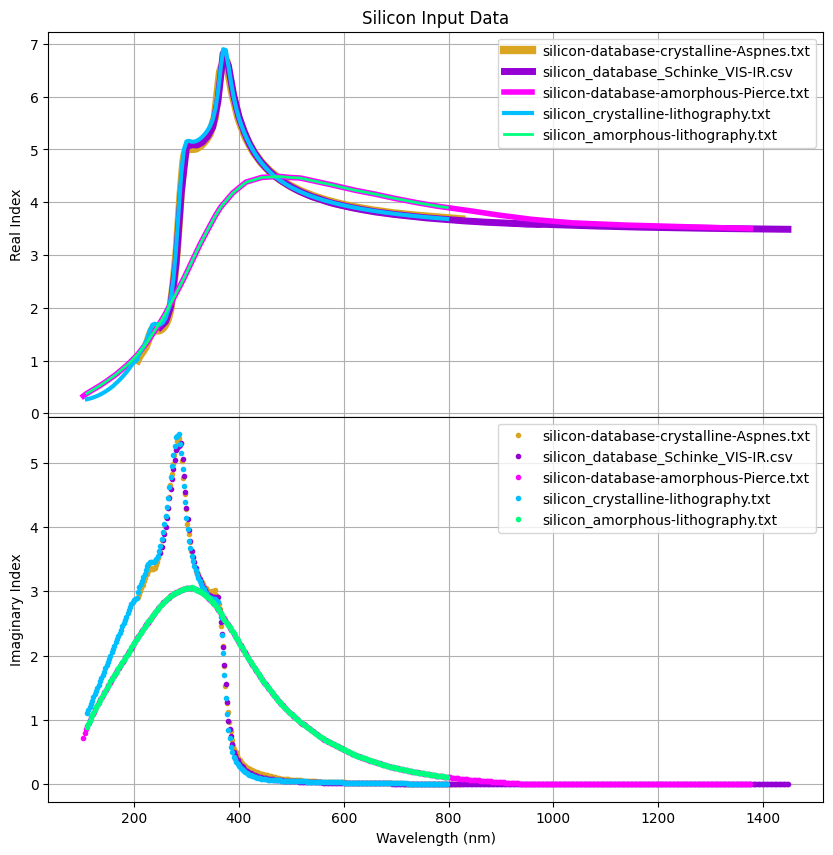

In [7]:
## plotting all Si data
fig, (axn, axk) = plt.subplots(2, 1, figsize=(10, 10), sharex = True)
ms.ResetColorCycle()

for i, file_name in enumerate(silicon_files):
    print(file_name)
    
    dh = OpticsData(siDataPath = os.path.join(directory, file_name), oxideDataPath="opticsData/"+silicon_oxide_files[0])
    wlens = np.arange(min(dh.dataWlenSi), max(dh.dataWlenSi), 2.5)

    lw = len(silicon_files) -i + 1
    shortFileName = os.path.basename(file_name).split(".")[0]
    axn.plot(wlens, np.real(dh.SiIndex(wlens)), linewidth = lw, color = ms.GetNextColor(), label = os.path.basename(dh.mPathSi))
    axk.plot(wlens, np.imag(dh.SiIndex(wlens)), linewidth = lw, color = ms.GetNextColor(1), linestyle = "None", marker=".", label = file_name)


axk.set_xlabel("Wavelength (nm)")
axn.set_ylabel("Real Index")
axk.set_ylabel("Imaginary Index")
axn.set_title("Silicon Input Data")

# axk.set_ylim(0, 0.3)
# axk.set_xlim(400, 600)
# axk.set_ylim(1e-2, 1)
# axk.set_yscale("log")

axn.legend()
axk.legend()
axn.grid()
axk.grid()
plt.subplots_adjust(hspace=0)
plt.show()

---
### Merging Si data

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_crystalline-lithography.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data is in um, converting to nm
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_database_Schinke_VIS-IR.csv
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/..

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_11430/3353365512.py:71: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axZoom.legend(title = "Merged region")
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_11430/3353365512.py:89: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axkZoom.legend(title = "Merged region")
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_11430/3353365512.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


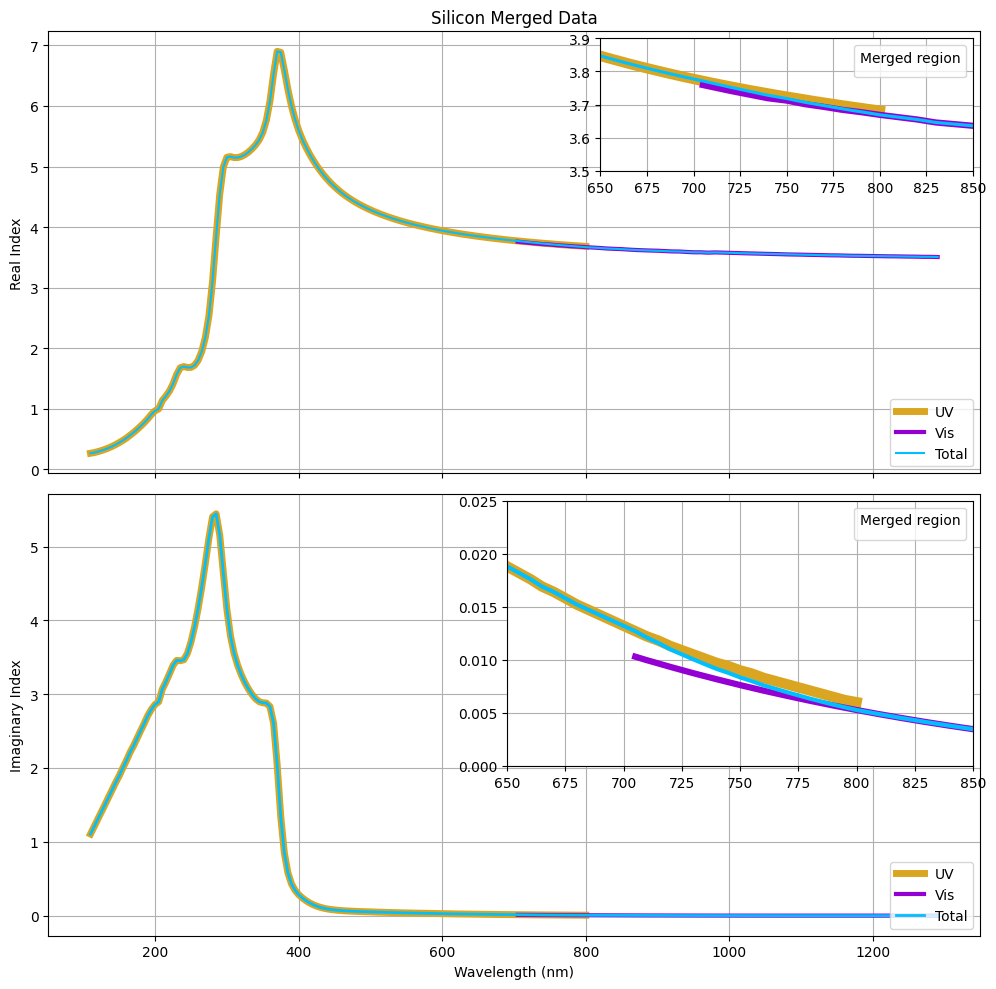

In [8]:
## mergin Silicon data with malitson

dhUV = OpticsData(siDataPath = os.path.join(directory, silicon_files[3]))
dhVis = OpticsData(siDataPath = os.path.join(directory, silicon_files[1]))

# we have two data objects
print("---- both paths ----")
print(dhUV.mPathSi)
print(dhVis.mPathSi)
print("---------------")

# the new array is ordered like
# uV1, (uv2, vis1), vis2
# the overlapping uv2, vis1 are averaged

# size in wl to average over
preStep = 100
# postStep = 25

xWlenUV = dhUV.dataWlenSi
yUV = dhUV.SiIndex(xWlenUV)

xUv1 = xWlenUV[xWlenUV <= max(xWlenUV) - preStep] #overlap region
yUV1 = yUV[xWlenUV <= max(xWlenUV) - preStep]

xUv2 = xWlenUV[xWlenUV > max(xWlenUV) - preStep]
yUV2 = yUV[xWlenUV > max(xWlenUV) - preStep]

visStep = 10
xVis1 = xUv2 # overlap region
yVis1 = dhVis.SiIndex(xVis1)

xVis2 = np.arange(max(xUv2) + visStep, 1300, visStep)
yVis2 = dhVis.SiIndex(xVis2)

xVis = np.concatenate((xVis1, xVis2))
yVis = np.concatenate((yVis1, yVis2))

# weighted average areas 1 and 2
weights_A = np.linspace(1, 0, len(xUv2))
weights_B = np.linspace(0, 1, len(xVis1))

# Calculate the weighted averages
middleYs = weights_A * yUV2 + weights_B * yVis1

totalXs = np.concatenate((xUv1, xUv2, xVis2))
totalYs = np.concatenate((yUV1, middleYs, yVis2))

data = np.column_stack((totalXs, np.real(totalYs), np.imag(totalYs)))
fmt = ['%.2f', '%.4f', '%.2e']
# np.savetxt('silicon_crystalline_lithoAndSchinke_merged.txt', data, fmt = fmt, delimiter=',', header='wl(nm), n, k data. From Lithograph webpage and Schinke, merged at 800')


print("---------------")


fig, (axn, axk) = plt.subplots(2, 1, figsize=(10, 10), sharex = True)
ms.ResetColorCycle()
axn.plot(xWlenUV, np.real(yUV), color = ms.GetNextColor(), linewidth = 5, label = "UV")
axn.plot(xVis, np.real(yVis), color = ms.GetNextColor(), linewidth = 3, label = "Vis")
color = ms.GetNextColor()
axn.plot(totalXs, np.real(totalYs), color = ms.GetNextColor(), linewidth = 1.5,label = "Total")

# merged region, inset axis
axZoom = inset_axes(axn, width="40%", height="30%", loc='upper right')
for line in axn.get_lines():
    axZoom.plot(line.get_xdata(), line.get_ydata(), linewidth = line.get_linewidth()*1.5, color = line.get_color())
axZoom.set_ylim(3.5, 3.9)
axZoom.set_xlim(650, 850)
axZoom.grid()
axZoom.legend(title = "Merged region")

axn.legend(loc="lower right")

## k data ##
ms.ResetColorCycle()
axk.plot(xWlenUV, np.imag(yUV), color = ms.GetNextColor(),linewidth = 5, label = "UV")
axk.plot(xVis, np.imag(yVis), color = ms.GetNextColor(), linewidth = 3, label = "Vis")
ms.GetNextColor()
axk.plot(totalXs, np.imag(totalYs), color = ms.GetNextColor(), linewidth = 2, label = "Total")

# merged region, inset axis
axkZoom = inset_axes(axk, width="50%", height="60%", loc='upper right')
for line in axk.get_lines():
    axkZoom.plot(line.get_xdata(), line.get_ydata(), linewidth = line.get_linewidth()*1.5, color = line.get_color())
axkZoom.set_ylim(0.0, 0.025)
axkZoom.set_xlim(650, 850)
axkZoom.grid()
axkZoom.legend(title = "Merged region")

axk.legend(loc="lower right")

axk.set_xlabel("Wavelength (nm)")
axn.set_ylabel("Real Index")
axk.set_ylabel("Imaginary Index")
axn.set_title("Silicon Merged Data")

axn.grid()
axk.grid()

plt.tight_layout()
plt.show()

---
### Oxide data

Error loading silicon data: opticsData/silicon-database-crystalline-Aspnes.txt not found.
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_oxide-lithography-UV.txt
loaded and interpolated successfully.
-----------------------------
Error loading silicon data: opticsData/silicon-database-crystalline-Aspnes.txt not found.
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_oxide-lithography-VUV.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
------------------------

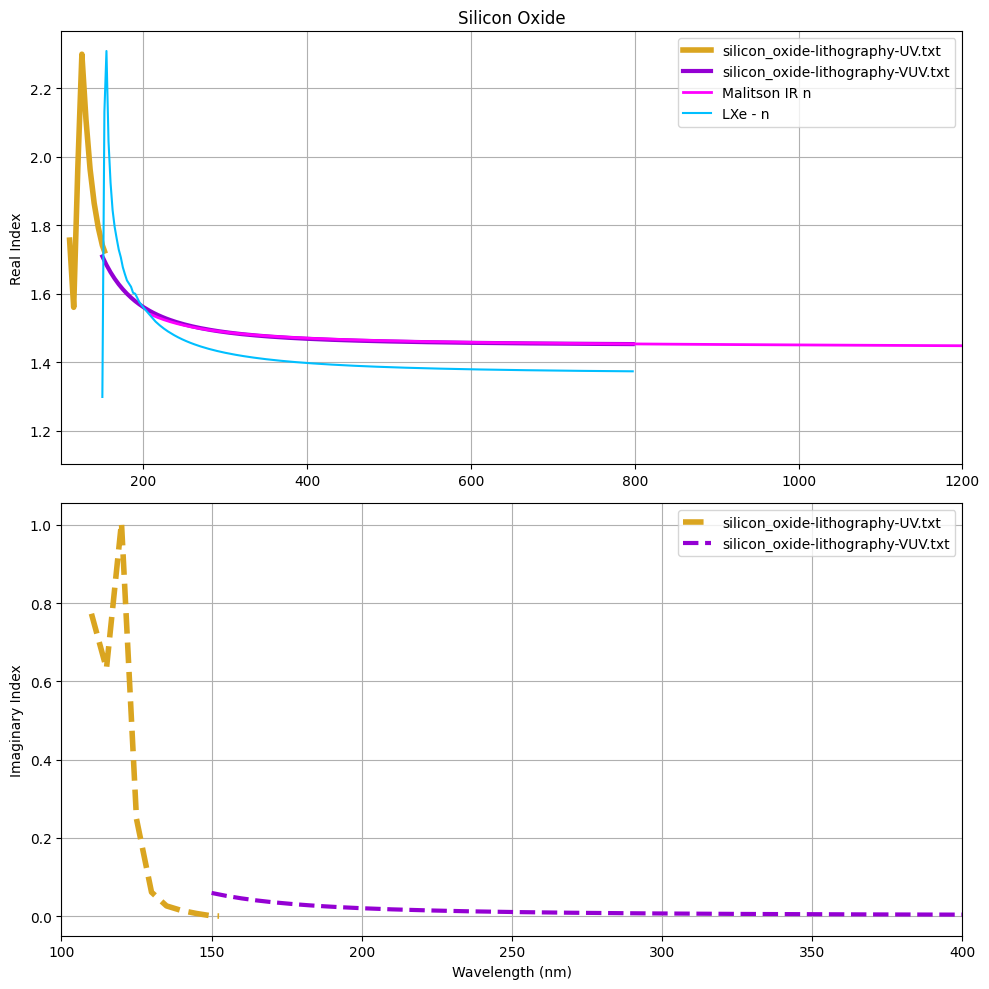

In [9]:
## plotting all oxide data

fig, (axn, axk) = plt.subplots(2, 1, figsize=(10, 10))
ms.ResetColorCycle()

wlens = np.arange(100, 1100, 2.5)
for i, file_name in enumerate(silicon_oxide_files):
    
    dh = OpticsData(siDataPath="opticsData/"+silicon_files[0], oxideDataPath = os.path.join(directory, file_name))
    wlens = np.arange(min(dh.dataWlenOxide), max(dh.dataWlenOxide), 2.5)

    lw = len(silicon_oxide_files) -i + 2
    axn.plot(wlens, np.real(dh.OxideIndex(wlens)), linewidth = lw, color = ms.GetNextColor(), label = file_name)
    axk.plot(wlens, np.imag(dh.OxideIndex(wlens)), linewidth = lw, color = ms.GetNextColor(1), linestyle = "--", label = file_name)


soMalitson = np.loadtxt(os.path.join(directory, "SingleColumns/silicon_oxide_MalitsonIR_onlyn.csv"),skiprows=1, delimiter = ',')
axn.plot(soMalitson[:,0]*1e3, soMalitson[:,1],  linewidth = lw -1, color = ms.GetNextColor(), label = "Malitson IR n")


dhLXe = OpticsData() 
dhLXe.Load_LXe_nData()
axn.plot(wlens, dhLXe.LXeIndex(wlens), color = ms.GetNextColor(), label = "LXe - n")

axn.legend()
axk.legend()
axn.grid()
axk.grid()

axk.set_xlabel("Wavelength (nm)")
axn.set_ylabel("Real Index")
axk.set_ylabel("Imaginary Index")
axn.set_title("Silicon Oxide")

axn.set_xlim(100, 1200)

axk.set_xlim(100, 400)

plt.tight_layout()
plt.show()

---
### Manipulating and Merging Silicon dioxide data

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_11430/3838692671.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axZoom.legend(title = "Merged region")


new n data 154 154
clear k data 154 154
foggy k data 154 138


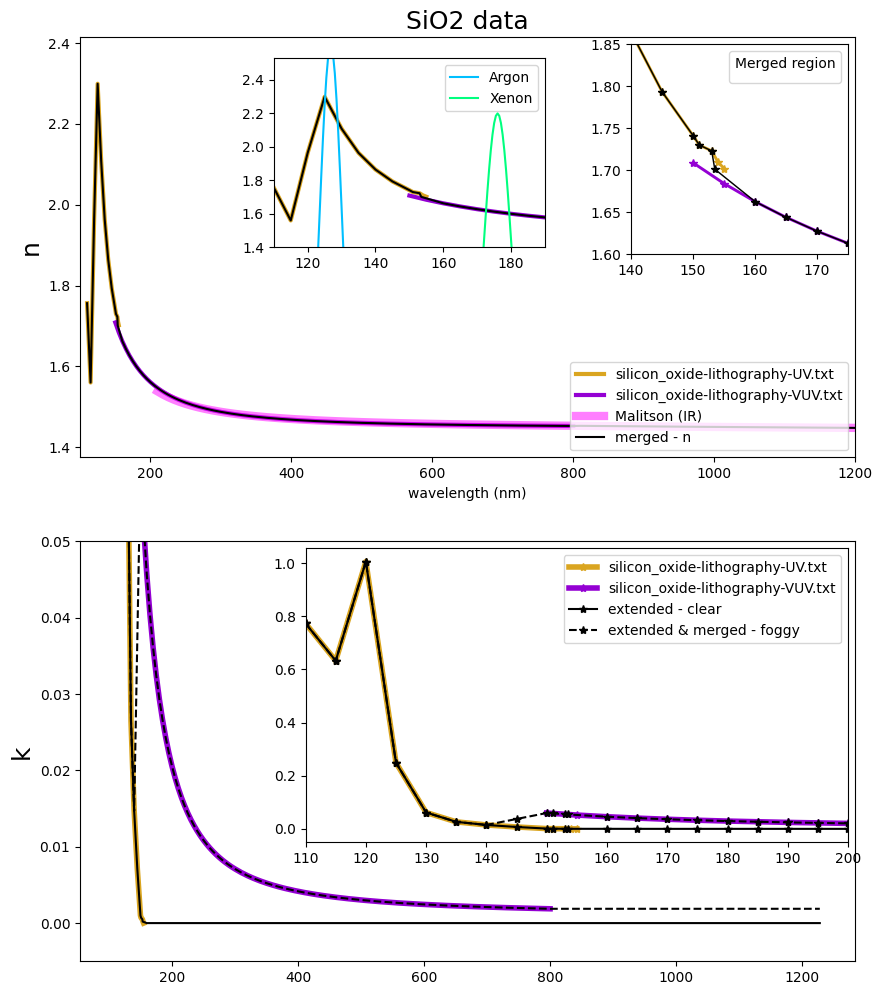

In [10]:
## Loading raw data
so1 = np.loadtxt(os.path.join(directory, silicon_oxide_files[0]), skiprows=1, delimiter = ',')
so2 = np.loadtxt(os.path.join(directory, silicon_oxide_files[1]), skiprows=1, delimiter = ',')
soMalitson = np.loadtxt(os.path.join(directory, "SingleColumns/silicon_oxide_MalitsonIR_onlyn.csv"), skiprows=1, delimiter = ',')
soMalitson[:, 0] *= 1e3 # convert to nm

# plot the raw data
ms.ResetColorCycle()
fig, (axn, axk) = plt.subplots(2, 1, figsize = (10, 12))
fs = 18

axn.plot(so1[:,0], so1[:,1], color = ms.GetNextColor(), linewidth = 3, label = silicon_oxide_files[0])
axn.plot(so2[:,0], so2[:,1], color = ms.GetNextColor(), linewidth = 3, label = silicon_oxide_files[1])
axn.plot(soMalitson[:,0], soMalitson[:,1], color = ms.GetNextColor(), linewidth = 6, alpha = 0.5, label = "Malitson (IR)")

### merging n data between UV and VUV regions
mN = 2
meanX = np.mean([so1[-mN:,0], so2[:mN,0]])
meanY = np.mean([so1[-mN:,1], so2[:mN,1]])
meanY_k = np.mean([so1[-mN:,2], so2[:mN,2]])

irMask = soMalitson[:,0] > max(so2[:,0])

newXs = np.concatenate((so1[:-mN,0], [meanX], so2[mN:,0], soMalitson[irMask,0]))
newYs = np.concatenate((so1[:-mN,1], [meanY], so2[mN:,1], soMalitson[irMask,1]))

rangeMask = (newXs > 100) & (newXs <= 1250)
newXs = newXs[rangeMask]
newYs = newYs[rangeMask]

## merged n data
axn.plot(newXs, newYs, color = "k", label = "merged - n")

# merged region, inset axis
axZoom = inset_axes(axn, width="28%", height="50%", loc='upper right')
for line in axn.get_lines():
    axZoom.plot(line.get_xdata(), line.get_ydata(), linewidth = line.get_linewidth()*0.7, marker = "*", color = line.get_color())
axZoom.set_ylim(1.6, 1.85)
axZoom.set_xlim(140, 175)
axZoom.legend(title = "Merged region")

## adding argon and xenon peaks and inset axis
axZoom2 = inset_axes(axn, width="100%", height="100%", bbox_to_anchor=(0.25, 0.5, 0.35, 0.45), bbox_transform=axn.transAxes, borderpad=0)
for line in axn.get_lines():
    axZoom2.plot(line.get_xdata(), line.get_ydata(), linewidth = line.get_linewidth(), color = line.get_color())

xAr = np.arange(110, 140, 0.5)
yAr = norm.pdf(xAr, 126.8, 7.8/2.35)
axZoom2.plot(xAr, yAr/max(yAr) * 2.6, color = ms.GetNextColor(), label = "Argon")
xXe = np.arange(160, 185, 0.5)
yXe = norm.pdf(xXe, 176, 10.2/2.35)
axZoom2.plot(xXe, yXe/max(yXe) * 2.2, color = ms.GetNextColor(), label = "Xenon")
axZoom2.set_ylim(1.4, 1.1*max(newYs))
axZoom2.set_xlim(110, 190)
axZoom2.legend()

axn.set_xlim(100, 1200)
axn.set_ylim(0.95*min(newYs), 1.05 * max(newYs))
axn.set_ylabel("n" , fontsize = fs)
axn.set_xlabel("wavelength (nm)")
axn.set_title("SiO2 data", fontsize = fs)
axn.legend(loc='lower right')


########## k data ##########
ms.ResetColorCycle()
axk.plot(so1[:,0], so1[:,2], linewidth = 4 ,color = ms.GetNextColor(), label = silicon_oxide_files[0])
axk.plot(so2[:,0], so2[:,2], linewidth = 4 ,color = ms.GetNextColor(), label = silicon_oxide_files[1])

# newXs also work here
newYs_k_clear = np.concatenate((so1[:,2], (len(newXs) - len(so1[:,2]))*[0]))

newXs_k_foggy = np.concatenate((so1[:-6,0], so2[0:, 0]))
newYs_k_foggy = np.concatenate((so1[:-6,2], so2[0:, 2]))
# newYs_k_foggy = np.concatenate((newYs_k_foggy, (len(newXs) - len(newYs_k_foggy))*[newYs_k_foggy[-1]]))

print("new n data", len(newXs), len(newYs))
print("clear k data", len(newXs), len(newYs_k_clear))
print("foggy k data", len(newXs), len(newYs_k_foggy))

int_foggy = interp1d(newXs_k_foggy, newYs_k_foggy, kind = "linear", bounds_error = False, fill_value=(newYs_k_foggy[0], newYs_k_foggy[-1]))
inted_newYs_k_foggy = int_foggy(newXs)

axk.plot(newXs, newYs_k_clear, color = "k", label = "extended - clear")
axk.plot(newXs, inted_newYs_k_foggy, color = "k", linestyle = "--", label = "extended & merged - foggy")

axk_zoom = inset_axes(axk, width="70%", height="70%", loc='upper right')
for line in axk.get_lines():
    axk_zoom.plot(line.get_xdata(), line.get_ydata(), marker = "*", linewidth = line.get_linewidth(), color = line.get_color(), label = line.get_label(), linestyle = line.get_linestyle())
axk_zoom.legend()
axk_zoom.set_xlim(110, 200)

axk.set_ylim(-0.005, 0.05)
axk.set_ylabel("k", fontsize = fs)

# np.savetxt("silicon_dioxide-merged-clear.txt", np.column_stack((newXs, newYs, newYs_k_clear)), fmt = "%.4f",delimiter=',', header='wl(nm), n, k - n is merged lithography datasets, malitson past 800nm, k is lithography UV set to zero after 150nm')
# np.savetxt("silicon_dioxide-merged-foggy.txt", np.column_stack((newXs, newYs, inted_newYs_k_foggy)), fmt = "%.4f", delimiter=',', header='wl(nm), n, k - n is merged lithography datasets, malitson past 800nm, k is lithography UV set to zero after 150nm')



plt.show()

---
---
### W values for different Datasets



['silicon-database-crystalline-Aspnes.txt', 'silicon_database_Schinke_VIS-IR.csv', 'silicon-database-amorphous-Pierce.txt', 'silicon_crystalline-lithography.txt', 'silicon_amorphous-lithography.txt']
silicon-database-crystalline-Aspnes.txt
-----------------------------
Silicon data is in um, converting to nm
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon-database-crystalline-Aspnes.txt
loaded and interpolated successfully.
-----------------------------
Error loading silicon oxide data: opticsData/silicon-database-crystalline-Aspnes.txt not found.
silicon_database_Schinke_VIS-IR.csv
-----------------------------
Silicon data is in um, converting to nm
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_database_Schinke_VIS-IR.csv
loaded and interpolated successfully.
-----------------------------
Error loading silico

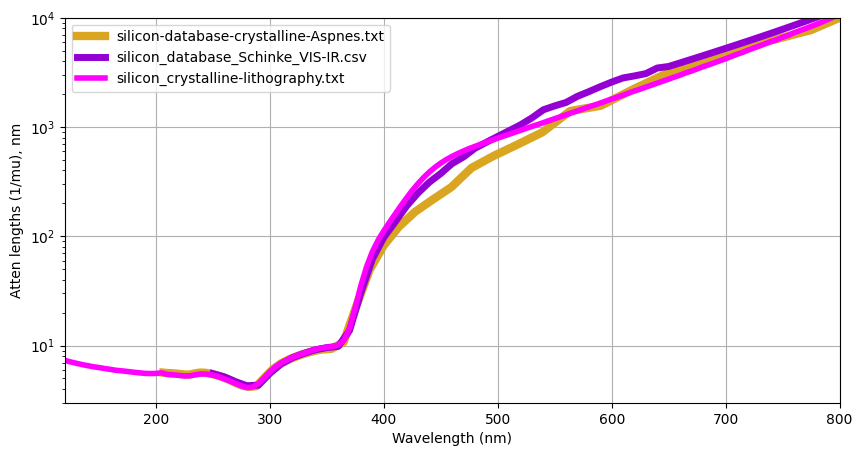

In [11]:
fig, axk = plt.subplots(1, 1, figsize=(10, 5), sharex = True)
ms.ResetColorCycle()

print(silicon_files)
silicon_filesC = [file_name for file_name in silicon_files if 'amorph' not in file_name]

for i, file_name in enumerate(silicon_filesC):
    print(file_name)
    
    dh = OpticsData(siDataPath = os.path.join(directory, file_name), oxideDataPath="opticsData/"+file_name)
    
    muVals = ME.Mu_fromIndex(dh.dataWlenSi, dh.SiIndex(dh.dataWlenSi))

    lw = len(silicon_files) -i + 1
    axk.plot(dh.dataWlenSi, 1/muVals, linewidth = lw, color = ms.GetNextColor(), linestyle = "-", label = file_name)

axk.set_xlabel("Wavelength (nm)")
axk.set_ylabel("Atten lengths (1/mu), nm")

# axk.set_ylim(0, 0.3)
axk.set_xlim(120, 800)
axk.set_ylim(3, 1e4)
axk.set_yscale("log")

axk.legend()
axk.grid()
plt.subplots_adjust(hspace=0)
plt.show()

### Merging into a good Aspnes dataset

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/silicon_crystalline-lithography.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerge

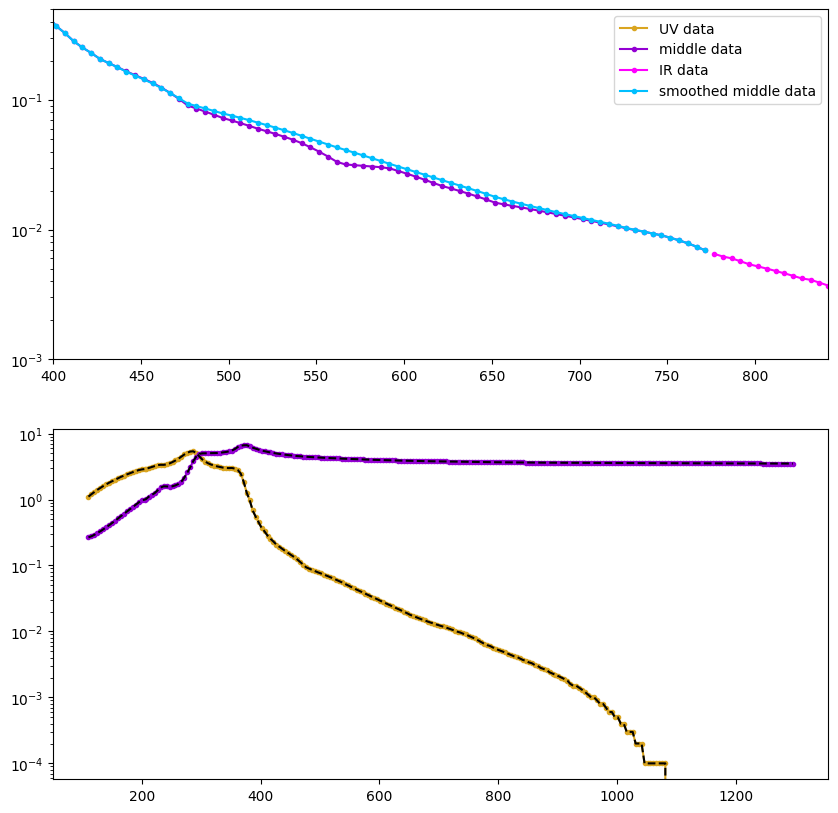

In [12]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import windows

dh.ResetInstance()
dhStandard = OpticsData()

### making a complete Si dataset with UV, Aspnes and Malitson data.
fUV = silicon_files[3]
dhUV = OpticsData(siDataPath = os.path.join(directory, fUV))

fAspnes = silicon_files[0]
dhMiddle = OpticsData(siDataPath = os.path.join(directory, fAspnes))

fIR = silicon_files[1]
dhIR = OpticsData(siDataPath = os.path.join(directory, fIR))
print(fUV, fAspnes, fIR)

# merging goes
# xp1 - xp2 (fUV)
# xp2 - xp3 fAspens
# xp3 - xp4 fIR

# x overlap points
xp1 = min(dhUV.dataWlenSi)
xp2 = min(dhMiddle.dataWlenSi)

overLapMid = 35
xp3=max(dhMiddle.dataWlenSi) - overLapMid - 50
xp4 = 1300

print(xp1, xp2, xp3, xp4)

xUV = dhUV.dataWlenSi[(dhUV.dataWlenSi < xp2)]
yUV = dhUV.SiIndex(xUV)

xMiddle = dhMiddle.dataWlenSi[(dhMiddle.dataWlenSi >= xp2) & (dhMiddle.dataWlenSi <= xp3 + overLapMid)]
xMiddle = np.arange(xp2, xp3 + overLapMid, 5)
yMiddle = dhMiddle.SiIndex(xMiddle)

# xIR = dhIR.dataWlenSi[(dhIR.dataWlenSi > xp3) & (dhIR.dataWlenSi <= xp4)]
# yIR = dhIR.SiIndex(xIR)
# xIR = dhStandard.dataWlenSi[(dhStandard.dataWlenSi > xp3 - overLapMid) & (dhStandard.dataWlenSi <= xp4)]
xIR = np.arange(xp3-overLapMid, xp4, 5)
yIR = dhStandard.SiIndex(xIR)

## Smooth IR and Middle data together where they overlap
yMid_imag = np.imag(yMiddle)
yMid_real = np.real(yMiddle)

indiceMiddleOverlap = np.where(xMiddle >= min(xIR))[0][0]
indiceIROverlap = np.where(xIR >= max(xMiddle))[0][0]
print(indiceMiddleOverlap)
print(xMiddle[indiceMiddleOverlap])

print(indiceIROverlap)
print(xIR[indiceIROverlap])

print(len(yMiddle[indiceMiddleOverlap:]) == len(yIR[:indiceIROverlap+1]))

window = np.linspace(0, 1, indiceIROverlap+1)
averagedOverlap = yMiddle[indiceMiddleOverlap:] * (1-window) + yIR[:indiceIROverlap+1] * window
yMiddle[indiceMiddleOverlap:] = averagedOverlap

newMid = yMiddle.copy()

## now truncate IR data
xIR = xIR[indiceIROverlap+1:]
yIR = yIR[indiceIROverlap+1:]

## now do my smoothing of bumps around 500

# where to apply smoothing to middle
startSmoothing = 425
stopSmoothing = 750
xILike = newMid[(xMiddle > startSmoothing) & (xMiddle < stopSmoothing)]
yILike = newMid[(xMiddle > startSmoothing) & (xMiddle < stopSmoothing)]

yILike_sm = gaussian_filter1d(yILike, 10)
window = windows.hann(len(yILike))
yWindow = yILike * (1-window) + yILike_sm * window # convolve it with original data so endpoints are not changed


newMid[(xMiddle > startSmoothing) & (xMiddle < stopSmoothing)] = yWindow


## plotting

fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (10, 10))

ax1.semilogy(xUV, np.imag(yUV), marker = ".", label = "UV data")
ax1.semilogy(xMiddle, np.imag(yMiddle), marker = ".", label = "middle data")
ax1.semilogy(xIR, np.imag(yIR), marker = ".", label = "IR data")

ax1.semilogy(xMiddle, np.imag(newMid), marker = ".", label = "smoothed middle data")

ax1.legend()

ax1.set_xlim(400, xp3 + 100)
ax1.set_ylim(0.001, 0.5)

### full stuff
xFull = np.concatenate((xUV, xMiddle, xIR))
yFull = np.concatenate((yUV, newMid, yIR))

ax2.semilogy(xFull, np.imag(yFull), marker = ".", label = "k data")
ax2.semilogy(xFull, np.real(yFull), marker = ".", label = "n data")


standardK = dhStandard.SiIndex(dhStandard.dataWlenSi).imag
standardN = dhStandard.SiIndex(dhStandard.dataWlenSi).real
ax2.semilogy(dhStandard.dataWlenSi, standardN, color = "k", linestyle = "--", label = "Standard data")
ax2.semilogy(dhStandard.dataWlenSi, standardK, color = "k", linestyle = "--", label = "Standard data")

plt.show()

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/si_vuye_300k.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_11430/322713977.py:8: RuntimeWarning: divide by zero encountered in divide
  plt.semilogy(xFull, 1/yMus, label = "1/mu")


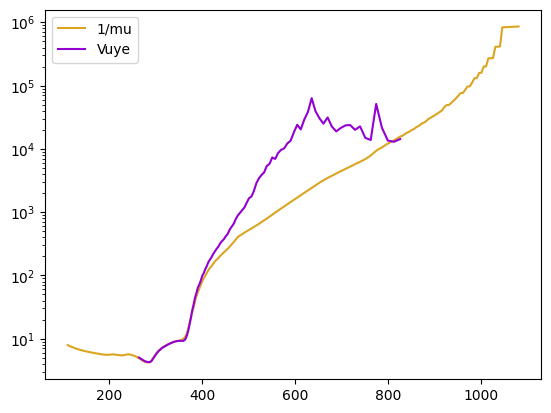

In [13]:
yMus = ME.Mu_fromIndex(xFull, yFull)

dh_vuye = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "si_vuye_300k.txt"))
ymu_vuye = ME.Mu_fromIndex(dh_vuye.dataWlenSi, dh_vuye.SiIndex(dh_vuye.dataWlenSi))

# np.savetxt("silicon_merged_AspnesMiddle.txt", np.column_stack((xFull, np.real(yFull), np.imag(yFull))), fmt = "%.4f", delimiter = ',', header = "wl(nm), n, k - merged from Lithography (UV-200nm), Aspnes to 600nm, default data (schinke past 600, malitson past 800))")

plt.semilogy(xFull, 1/yMus, label = "1/mu")

plt.semilogy(dh_vuye.dataWlenSi, 1/ymu_vuye, label = "Vuye")
plt.legend()